# 3. Analyse descriptive des données

Objectif : comprendre les tendances du harcèlement social dans le jeu de données
nettoyé — répartition des classes, sous-catégories de harcèlement les plus
fréquentes, longueur des messages, vocabulaire caractéristique de chaque classe.

## Chargement des données depuis MongoDB

In [1]:
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from pymongo import MongoClient
from pymongo.errors import ServerSelectionTimeoutError

pd.set_option("display.max_colwidth", 120)
sns.set_style("whitegrid")

load_dotenv("../.env")

MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")
MONGO_DB_NAME = os.getenv("MONGO_DB_NAME", "cyberbullying_db")
MONGO_COLLECTION_PROCESSED = os.getenv("MONGO_COLLECTION_PROCESSED", "messages_processed")
PROCESSED_CSV_PATH = "../data/processed/cyberbullying_clean.csv"

In [2]:
# On charge en priorité depuis MongoDB (étape 2 du pipeline). Si l'instance
# n'est pas disponible, on retombe sur le CSV nettoyé du notebook 01 pour ne
# pas bloquer l'analyse.
try:
    client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=3000)
    client.admin.command("ping")
    collection = client[MONGO_DB_NAME][MONGO_COLLECTION_PROCESSED]
    df = pd.DataFrame(list(collection.find({}, {"_id": 0})))
    print(f"Données chargées depuis MongoDB ({MONGO_DB_NAME}.{MONGO_COLLECTION_PROCESSED}) : {len(df)} lignes")
except ServerSelectionTimeoutError:
    df = pd.read_csv(PROCESSED_CSV_PATH)
    print(f"MongoDB indisponible, données chargées depuis {PROCESSED_CSV_PATH} : {len(df)} lignes")

df.head()

Données chargées depuis MongoDB (cyberbullying_db.messages_processed) : 5740 lignes


,Text,text_clean,Label,Types,text_len
0,Ten outside soon doctor shake everyone treatment seat radio land.,ten outside soon doctor shake everyone treatment seat radio land,Not-Bullying,Aucun,10
1,my life has come to a standstill and at this point.,my life has come to a standstill and at this point,Not-Bullying,Aucun,11
2,girl this nigga make me sick to my stomach,girl this nigga make me sick to my stomach,Bullying,Ethnicity,9
3,I wanna fuck you,i wanna fuck you,Bullying,Sexual,4
4,"Oh hey, you should be ashamed of your disgusting self",oh hey you should be ashamed of your disgusting self,Not-Bullying,Aucun,10


## Statistiques descriptives

In [3]:
print("Dimensions :", df.shape)
df.info()

Dimensions : (5740, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5740 entries, 0 to 5739
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Text        5740 non-null   object
 1   text_clean  5740 non-null   object
 2   Label       5740 non-null   object
 3   Types       5740 non-null   object
 4   text_len    5740 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 224.3+ KB


In [4]:
# Statistiques globales sur la longueur des messages (en mots)
df["text_len"].describe()

count    5740.000000
mean        9.588328
std         4.748056
min         1.000000
25%         6.000000
50%         9.000000
75%        12.000000
max        52.000000
Name: text_len, dtype: float64

In [5]:
# Statistiques de longueur, par classe
df.groupby("Label")["text_len"].describe()

,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
Bullying,3140.0,9.429936,4.494292,1.0,6.0,9.0,12.0,43.0
Not-Bullying,2600.0,9.779615,5.031747,1.0,5.0,10.0,13.0,52.0


## Distribution des classes

              count   pct
Label                    
Bullying       3140  54.7
Not-Bullying   2600  45.3


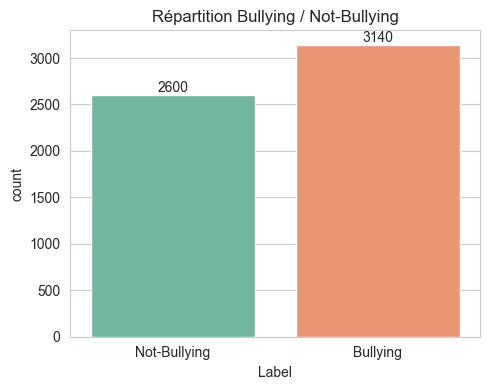

In [6]:
label_counts = df["Label"].value_counts()
label_pct = df["Label"].value_counts(normalize=True) * 100

print(pd.DataFrame({"count": label_counts, "pct": label_pct.round(1)}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Label", hue="Label", palette="Set2", legend=False, ax=ax)
ax.set_title("Répartition Bullying / Not-Bullying")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

             count   pct
Types                   
Troll          805  25.6
Sexual         658  21.0
Vocational     464  14.8
Political      463  14.7
Religion       403  12.8
Threats        197   6.3
Ethnicity      125   4.0
Non précisé     25   0.8


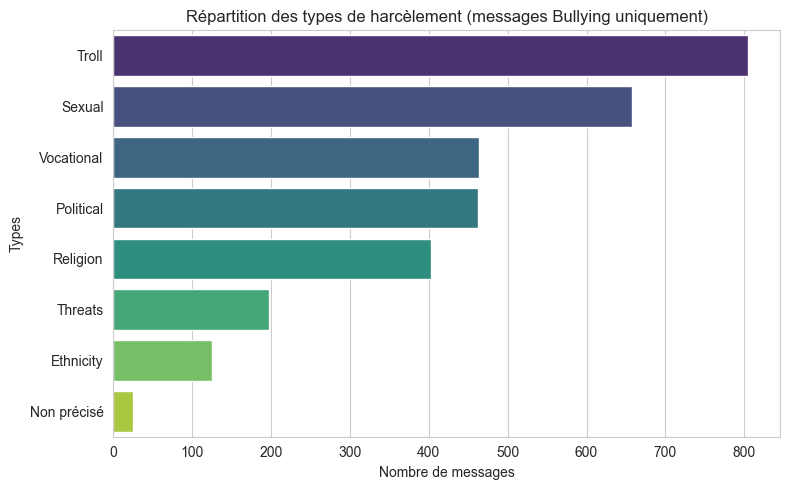

In [9]:
# Répartition des sous-catégories de harcèlement (hors messages "Aucun")
bullying_df = df[df["Label"] == "Bullying"]
types_counts = bullying_df["Types"].value_counts()
types_pct = (types_counts / types_counts.sum() * 100).round(1)

print(pd.DataFrame({"count": types_counts, "pct": types_pct}))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=types_counts.values, y=types_counts.index, hue=types_counts.index,
            palette="viridis", legend=False, ax=ax)
ax.set_title("Répartition des types de harcèlement (messages Bullying uniquement)")
ax.set_xlabel("Nombre de messages")
plt.tight_layout()
plt.show()

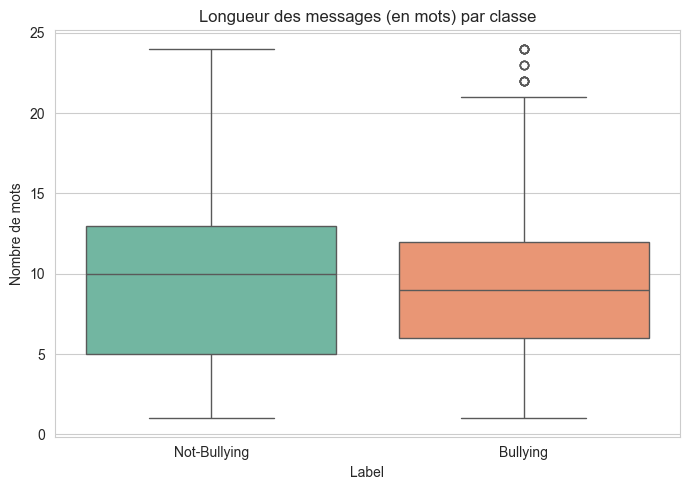

In [10]:
# Longueur des messages selon la classe
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df[df["text_len"] <= df["text_len"].quantile(0.99)],
            x="Label", y="text_len", hue="Label", palette="Set2", legend=False, ax=ax)
ax.set_title("Longueur des messages (en mots) par classe")
ax.set_ylabel("Nombre de mots")
plt.tight_layout()
plt.show()

## Analyse des tendances du harcèlement social

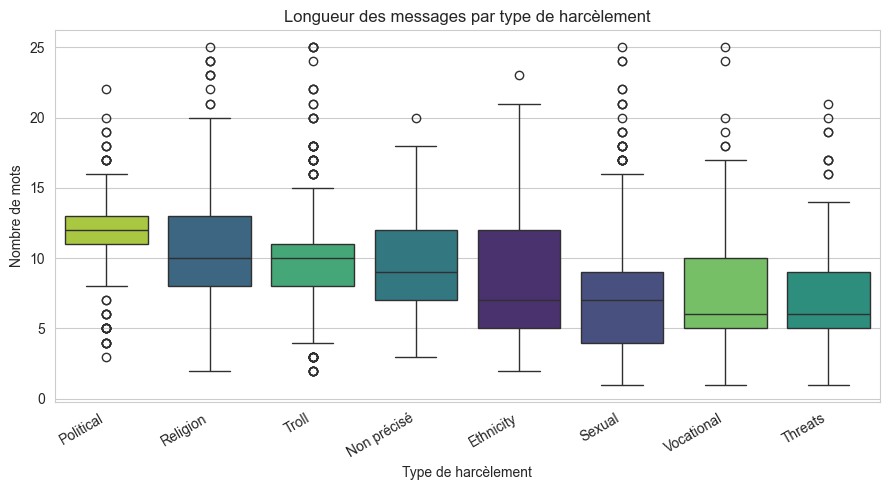

In [11]:
# Longueur moyenne des messages par type de harcèlement 
fig, ax = plt.subplots(figsize=(9, 5))
order = bullying_df.groupby("Types")["text_len"].median().sort_values(ascending=False).index
sns.boxplot(data=bullying_df[bullying_df["text_len"] <= bullying_df["text_len"].quantile(0.99)],
            x="Types", y="text_len", order=order, hue="Types", palette="viridis", legend=False, ax=ax)
ax.set_title("Longueur des messages par type de harcèlement")
ax.set_ylabel("Nombre de mots")
ax.set_xlabel("Type de harcèlement")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [12]:
STOPWORDS = {
    "the", "a", "an", "and", "or", "is", "are", "was", "were", "to", "of", "in",
    "on", "for", "it", "that", "this", "i", "you", "he", "she", "they", "we",
    "my", "your", "his", "her", "their", "our", "me", "him", "them", "us",
    "be", "been", "am", "so", "at", "as", "with", "not", "do", "does", "did",
    "have", "has", "had", "but", "just", "there", "than", "then", "s", "t",
}


def top_words(texts, n=12):
    counter = Counter()
    for text in texts:
        counter.update(w for w in str(text).split() if w not in STOPWORDS and len(w) > 1)
    return counter.most_common(n)


# Vocabulaire caractéristique de chaque type de harcèlement
for harass_type in types_counts.index:
    words = top_words(bullying_df.loc[bullying_df["Types"] == harass_type, "text_clean"])
    print(f"--- {harass_type} ---")
    print(", ".join(f"{w} ({c})" for w, c in words))
    print()

--- Troll ---
post (126), you're (118), humor (84), comedy (82), like (81), instagram (74), if (70), should (66), laughter (56), posts (40), day (36), from (35)

--- Sexual ---
want (51), you're (49), sexual (44), when (41), make (40), sex (38), i'll (34), fuck (32), hot (31), if (31), about (30), can't (30)

--- Vocational ---
you're (99), job (28), work (26), such (24), never (24), everyone (20), by (20), you'll (19), health (19), how (18), find (18), economy (18)

--- Political ---
political (152), public (61), undermines (51), leaders (46), government (46), who (42), lack (38), erosion (34), over (32), trust (31), neglect (31), threatens (29)

--- Religion ---
religious (149), can (144), religion (129), i'm (73), about (43), critical (36), fear (36), historical (34), sometimes (31), muslims (25), leaders (24), skeptical (23)

--- Threats ---
you're (32), everyone (13), kill (12), should (12), why (10), all (10), never (10), life (10), i'm (8), because (8), killed (7), don't (7)

--

In [13]:
# Nuage de fréquence sous forme de heatmap : proportion de chaque type de
# harcèlement, avec sa longueur moyenne, pour une vue synthétique des tendances
summary = bullying_df.groupby("Types").agg(
    nb_messages=("Types", "count"),
    pct_du_bullying=("Types", lambda s: round(len(s) / len(bullying_df) * 100, 1)),
    longueur_moyenne=("text_len", "mean"),
).sort_values("nb_messages", ascending=False)

summary["longueur_moyenne"] = summary["longueur_moyenne"].round(1)
summary

,nb_messages,pct_du_bullying,longueur_moyenne
Types,,,
Troll,805,25.6,10.1
Sexual,658,21.0,7.5
Vocational,464,14.8,7.9
Political,463,14.7,11.9
Religion,403,12.8,11.1
Threats,197,6.3,7.1
Ethnicity,125,4.0,9.6
Non précisé,25,0.8,9.9


### Synthèse

- Le jeu de données est globalement équilibré entre messages `Bullying` et `Not-Bullying`.
- Parmi les messages de harcèlement, les catégories `Sexual` et `Troll` dominent en volume.
- Les messages de harcèlement ont tendance à être plus courts que les messages neutres :
  cohérent avec des insultes directes plutôt que des phrases construites.
- Chaque sous-catégorie a un vocabulaire distinctif (ex : termes religieux pour `Religion`,
  termes à connotation sexuelle pour `Sexual`).